# Neural Network Basics: From a Perceptron to Gradient Descent

In this practice you will build the parts of a neural network by hand with NumPy: a perceptron, a single artificial neuron with an activation function, a small network with a hidden layer, and gradient descent to learn the weights.

Everything here uses only what Lesson 2 covers. The practice trains a single neuron; the lesson describes how backpropagation extends this to networks with hidden layers.

## Background

The lesson's perceptron uses three Boolean inputs, X1, X2 and X3, and produces an output y of 1 or −1. In this practice there is no dataset file: you will create all eight possible input combinations in code.

## 1. The Perceptron from the Lesson

The lesson's perceptron is:

y = 1 if 0.3X₁ + 0.3X₂ + 0.3X₃ − 0.4 > 0, and y = −1 otherwise.

It computes a weighted sum of the inputs, subtracts a bias of 0.4 and checks the sign of the result.

In [1]:
import numpy as np
import pandas as pd
from itertools import product

# All 8 combinations of three Boolean inputs
X = np.array(list(product([0, 1], repeat=3)))
X

array([[0, 0, 0],
       [0, 0, 1],
       [0, 1, 0],
       [0, 1, 1],
       [1, 0, 0],
       [1, 0, 1],
       [1, 1, 0],
       [1, 1, 1]])

In [2]:
weights = np.array([0.3, 0.3, 0.3])
bias = 0.4

def perceptron(x):
    weighted_sum = np.dot(x, weights) - bias
    return 1 if weighted_sum > 0 else -1

table = pd.DataFrame(X, columns=["X1", "X2", "X3"])
table["weighted sum - bias"] = np.round(X @ weights - bias, 2)
table["y"] = [perceptron(x) for x in X]
table

,X1,X2,X3,weighted sum - bias,y
0,0,0,0,-0.4,-1
1,0,0,1,-0.1,-1
2,0,1,0,-0.1,-1
3,0,1,1,0.2,1
4,1,0,0,-0.1,-1
5,1,0,1,0.2,1
6,1,1,0,0.2,1
7,1,1,1,0.5,1


The output is 1 whenever at least two of the three inputs are 1, because 0.3 + 0.3 = 0.6 is greater than 0.4, while 0.3 alone is not.

## 2. A Single Artificial Neuron, Step by Step

The lesson builds a single neuron in three steps: sum the inputs, weight them, then apply an activation (transfer) function. Here we use one input pattern.

In [3]:
x = np.array([1.0, 0.0, 1.0])

# Step 1: basic summation
print("Step 1, sum of inputs:", x.sum())

# Step 2: weighted inputs
w = np.array([0.5, -0.2, 0.8])
weighted = np.dot(x, w)
print("Step 2, weighted sum:", weighted)

# Step 3: add the bias and apply an activation function
b = -0.6
v = weighted + b
print("Step 3, weighted sum plus bias (v):", round(v, 2))

Step 1, sum of inputs: 2.0
Step 2, weighted sum: 1.3
Step 3, weighted sum plus bias (v): 0.7


The activation function introduces non-linearity. The lesson lists the sign, linear, sigmoid and tanh functions. Here is the neuron's output with each one.

In [4]:
def sign(v):    return np.where(v > 0, 1, -1)
def linear(v):  return v
def sigmoid(v): return 1 / (1 + np.exp(-v))

print("Sign output:   ", sign(v))
print("Linear output: ", round(linear(v), 3))
print("Sigmoid output:", round(sigmoid(v), 3))
print("Tanh output:   ", round(np.tanh(v), 3))

Sign output:    1
Linear output:  0.7
Sigmoid output: 0.668
Tanh output:    0.604


## 3. A Network with a Hidden Layer

In a feed-forward network, each hidden neuron has its own weighted sum and activation function, and the hidden outputs feed the output neuron. Here is a network with 3 inputs, 2 hidden neurons and 1 output, using the sigmoid function. Each column of `W_hidden` holds one hidden neuron's weights.

In [5]:
W_hidden = np.array([[0.2, -0.4],
                     [0.7,  0.1],
                     [-0.5, 0.6]])   # 3 inputs x 2 hidden neurons
b_hidden = np.array([0.1, -0.1])

w_output = np.array([0.9, -0.3])     # 2 hidden neurons -> 1 output
b_output = 0.05

def forward(x):
    hidden = sigmoid(x @ W_hidden + b_hidden)
    output = sigmoid(hidden @ w_output + b_output)
    return hidden, output

hidden, output = forward(np.array([1.0, 0.0, 1.0]))
print("Hidden layer outputs:", np.round(hidden, 3))
print("Network output:", round(output, 3))

Hidden layer outputs: [0.45  0.525]
Network output: 0.574


Running every input pattern through the network gives one output for each row.

In [6]:
_, outputs = forward(X)
pd.DataFrame({"X1": X[:, 0], "X2": X[:, 1], "X3": X[:, 2], "output": np.round(outputs, 3)})

,X1,X2,X3,output
0,0,0,0,0.594
1,0,0,1,0.556
2,0,1,0,0.627
3,0,1,1,0.592
4,1,0,0,0.612
5,1,0,1,0.574
6,1,1,0,0.643
7,1,1,1,0.610


These weights were chosen by hand, so the outputs are not yet useful. Training finds weights that make the outputs match the targets.

## 4. Measure the Error

Training aims to find the weights that minimise the **total sum of squared errors (SSE)** between the targets and the outputs. As targets, we use the perceptron's rule from Section 1, recoded to 1 and 0 so that they match the sigmoid's range.

In [7]:
targets = (table["y"].to_numpy() == 1).astype(float)

def sse(targets, outputs):
    return np.sum((targets - outputs) ** 2)

print("Targets:", targets)
print("SSE with the hand-picked weights:", round(sse(targets, outputs), 3))

Targets: [0. 0. 0. 1. 0. 1. 1. 1.]
SSE with the hand-picked weights: 2.057


## 5. Learn the Weights with Gradient Descent

Gradient descent updates each weight in the direction that reduces the error, scaled by the learning rate λ. For a single sigmoid neuron the update is:

w ← w + λ × Σ (target − output) × output × (1 − output) × x

(Differentiating the squared error also gives a factor of 2, which is absorbed into λ.)

We start a single neuron from small random weights and repeat the update.

In [8]:
rng = np.random.default_rng(42)
w = rng.normal(0, 0.1, size=3)
b = 0.0
learning_rate = 0.5

history = []
for epoch in range(2000):
    out = sigmoid(X @ w + b)
    error = targets - out
    delta = error * out * (1 - out)
    w += learning_rate * X.T @ delta
    b += learning_rate * delta.sum()
    history.append(sse(targets, out))

print("SSE at the start:", round(history[0], 3))
print("SSE after 2,000 updates:", round(history[-1], 3))
print("Learned weights:", np.round(w, 2), "bias:", round(b, 2))

SSE at the start: 2.001
SSE after 2,000 updates: 0.012
Learned weights: [6.09 6.09 6.09] bias: -9.06


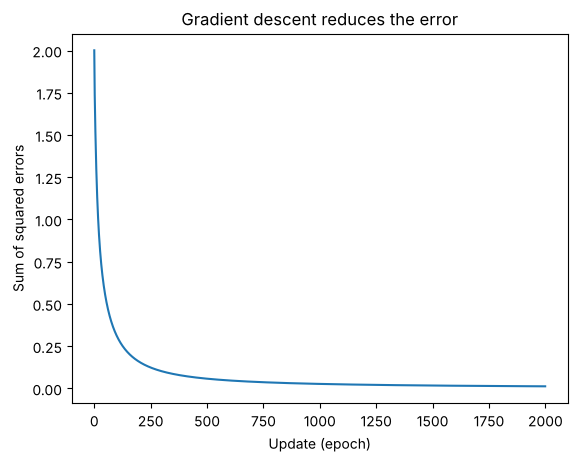

In [9]:
import matplotlib.pyplot as plt

plt.plot(history)
plt.xlabel("Update (epoch)")
plt.ylabel("Sum of squared errors")
plt.title("Gradient descent reduces the error")
plt.show()

The error falls quickly at first and then levels off. Check the trained neuron's predictions against the targets.

In [10]:
final = sigmoid(X @ w + b)
pd.DataFrame({"X1": X[:, 0], "X2": X[:, 1], "X3": X[:, 2],
              "target": targets, "output": np.round(final, 2),
              "predicted class": (final > 0.5).astype(int)})

,X1,X2,X3,target,output,predicted class
0,0,0,0,0.0,0.00,0
1,0,0,1,0.0,0.05,0
2,0,1,0,0.0,0.05,0
3,0,1,1,1.0,0.96,1
4,1,0,0,0.0,0.05,0
5,1,0,1,1.0,0.96,1
6,1,1,0,1.0,0.96,1
7,1,1,1,1.0,1.00,1


The neuron has learned the rule "at least two inputs are 1" from the examples alone. The three learned weights are equal, just as in the lesson's perceptron, because each input plays the same role.

For a network with hidden layers, the error at the hidden neurons cannot be measured directly. **Backpropagation** solves this: a forward phase computes every neuron's output, then a backward phase uses the chain rule to pass the error back through the layers and update the weights.

## Summary

- A perceptron computes a weighted sum, subtracts a bias and checks the sign.
- A neuron's output depends on its inputs, weights, bias and activation function.
- In a feed-forward network, hidden neurons each compute their own weighted sum and activation, and feed the output neuron.
- Training finds the weights that minimise the sum of squared errors, using gradient descent.
- Backpropagation extends gradient descent to hidden layers by passing the error backward.